# XAI lab: explaining model predictions

**Name:** Ahmad Adel Younus Ahmouda
**Version:** 5 October 2026 — revision 2

Use PDP/ICE, LIME and SHAP to explain one random forest that predicts employee
attrition (`1 = Yes`, `0 = No`). We will ask what each explanation shows and
how much it can be trusted. This is a teaching exercise, not a tool for making
decisions about real employees.

## How to work

- Complete **all four tasks**. There are no optional tasks and no separate report.
- Put this notebook and `Employee-Attrition.csv` in the same folder.
- Run cells in order. **Provided code** is ready to run. In the five
  **Starter code** cells, replace `...` as instructed. These cells will not work
  until you complete them. Also complete the **Your code** blocks: these require
  you to write the analysis, not just replace an argument.
- Keep the supplied model, split, seeds and sample sizes. In Task 2, choose two
  features from the stated list. Do not tune the model or add other experiments.
- Replace each **Your answer** prompt with your response. Use your own numbers,
  feature names and employee IDs. Usually 1–3 sentences per numbered question
  are enough. There is no word-count requirement.
- You may refer to this notebook during the written defense. Be ready to explain
  the small code operations and the meaning and limits of your results.

## Already started? What to update

**NEW** means an added required subtask. **REVISED** means that the instructions
or required implementation have changed. The labels below compare this notebook
with the original September / 2 October version.

| Section | Status | What to do |
|---|---|---|
| Setup, data, split, forest and selected employees | Unchanged | Keep your working code. Use the same model and cases throughout. |
| Task 1: original analysis | Unchanged | Keep your original results and answers 1–3. |
| Task 1: threshold comparison | NEW | Add the three-threshold table, error-count plot and answers 4–5. |
| Task 2: original PDP/ICE analysis | Unchanged | Keep your chosen features, plots, numerical check and answers 1–4. |
| Task 2: overtime-group comparison | NEW | Add the two-group table, centred-curve plot and answers 5–6. |
| Task 3: original LIME cases and 3,000-input repeat | Unchanged | Keep these results and answers 1–3. The questions now name the relevant runs more explicitly. |
| Task 3: 500-versus-5,000 comparison | NEW | Add the six-run experiment, summary, dot plot and answer 4. |
| Task 4A: waterfall plots and contribution table | REVISED | Same outputs, but now an implementation block. Adapt existing code if you already made them. |
| Task 4B: numerical checks | REVISED + NEW check | Keep the reconstruction check; complete its code and add the background-mean check. |
| Task 4C: background comparison | REVISED + NEW outputs | Extend the three 100-row runs to six runs using 20 and 100 rows. Add the range table, dot plot and revised answers. |

If you already have the earlier **5 October** revision with the LIME sample-count
comparison and expanded SHAP tasks, those requirements are unchanged here.
Only the Task 1 and Task 2 subtasks are newly added in revision 2.

**Keep completed work that meets the instructions.** You may copy it into this
version, or add the marked sections to your existing notebook. Do not discard
correct results just because the surrounding instructions have changed.
Original Task 4 answer 3 (LIME versus SHAP) is now answer 4. Old “Your prediction”
prompts are no longer required. Cell numbers have moved; use section headings.

## Setup — provided code

First run the imports below. If a package is missing, uncomment the two `%pip`
lines, run that cell, restart the kernel, and run the imports again. The listed
versions are the versions tested for this notebook. On JupyterHub, contact the
lecturer if package installation is disabled.

In [4]:
# Run only if the imports fail. Then restart the kernel.
# %pip install numpy==2.2.6 pandas==2.3.3 matplotlib==3.10.6 scikit-learn==1.7.2
# %pip install lime==0.2.0.1 shap==0.49.1
!pip install shap lime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]1/2 [shap]


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from importlib.metadata import version

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.metrics import ConfusionMatrixDisplay
from lime.lime_tabular import LimeTabularExplainer
import shap

SEED = 42
plt.rcParams["figure.dpi"] = 110
print({name: version(name) for name in ["numpy", "pandas", "scikit-learn", "lime", "shap"]})

{'numpy': '2.4.6', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'lime': '0.2.0.1', 'shap': '0.52.0'}


## Data — provided code

This small, fictional IBM employee dataset has 1,470 rows. We use ten features
to keep preprocessing and explanations short. `EmployeeNumber` is a row label
(employee ID), **not an input to the model**. `Attrition` is the target.

| Feature | Meaning / coding |
|---|---|
| Age | Age in years |
| MonthlyIncome | Monthly income, in the dataset's units |
| DistanceFromHome | Distance from home, in the dataset's units |
| TotalWorkingYears | Total years of work experience |
| YearsAtCompany | Years at the current company |
| YearsInCurrentRole | Years in the current role |
| JobSatisfaction, EnvironmentSatisfaction | 1 = Low, 2 = Medium, 3 = High, 4 = Very high |
| WorkLifeBalance | 1 = Bad, 2 = Good, 3 = Better, 4 = Best |
| OverTime | 0 = No, 1 = Yes |

The split is fixed: 75% for training and 25% for validation, with similar class
proportions in both. Fit the model on training rows; explain validation rows.

In [6]:
df = pd.read_csv("Employee-Attrition.csv").set_index("EmployeeNumber")
FEATURES = [
    "Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
    "YearsAtCompany", "YearsInCurrentRole", "JobSatisfaction",
    "EnvironmentSatisfaction", "WorkLifeBalance", "OverTime"
]
X = df[FEATURES].copy()
X["OverTime"] = X["OverTime"].map({"No": 0, "Yes": 1})
y = df["Attrition"].map({"No": 0, "Yes": 1})

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
print(f"Training rows: {len(X_train)}; validation rows: {len(X_valid)}")
print(f"Validation: Yes = {y_valid.mean():.1%}; No = {1 - y_valid.mean():.1%}")
display(X_train.head(3))

Training rows: 1102; validation rows: 368
Validation: Yes = 16.0%; No = 84.0%


,Age,MonthlyIncome,DistanceFromHome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,OverTime
EmployeeNumber,,,,,,,,,,
28,34,11994,7,13,12,6,2,1,3,0
97,36,3038,6,5,1,0,4,2,3,0
1878,22,2472,7,1,1,0,2,4,3,1


## Task 1 — check the model before explaining it

**Update:** the original analysis and answers 1–3 are unchanged. The threshold
comparison below and answers 4–5 are **NEW**.

**Question:** Does the model do more than predict the majority class?

Train the supplied random forest and compare it with the supplied baseline.
The baseline assigns everyone the training-set attrition rate. At a threshold
of 0.5, it predicts the majority class for everyone.

- **Accuracy:** fraction of correct class predictions, using threshold 0.5.
- **Average precision (AP):** summarises how well high scores identify attrition
  cases. Higher is better. A constant-score baseline has AP equal to the
  validation-set fraction of `Yes` cases.

**Required outputs:** the two-model metrics table, the forest's confusion matrix,
the table of two cases, and the **NEW** threshold table and error-count plot.

### Starter code 1/5

Replace `...` with the training inputs and training labels in `model.fit(...)`.
Keep the model settings unchanged.

In [9]:
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

model = RandomForestClassifier(
    n_estimators=100, max_depth=6, min_samples_leaf=5,
    random_state=SEED, n_jobs=1
)
model.fit(X_train,y_train)  # TODO: training inputs, training labels

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total num

### Starter code 2/5

Replace `...` with the validation inputs. `predict_proba` returns two columns,
for classes 0 and 1. `[:, 1]` selects the probability of attrition.

In [11]:
probability = model.predict_proba(X_valid)[:, 1]  # TODO: validation inputs
baseline_probability = baseline.predict_proba(X_valid)[:, 1]

rows = []
for name, scores in [("Baseline", baseline_probability), ("Random forest", probability)]:
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_valid, scores >= 0.5),
        "average precision": average_precision_score(y_valid, scores)
    })
display(pd.DataFrame(rows).set_index("model").round(3))

,accuracy,average precision
model,,
Baseline,0.840,0.160
Random forest,0.842,0.397


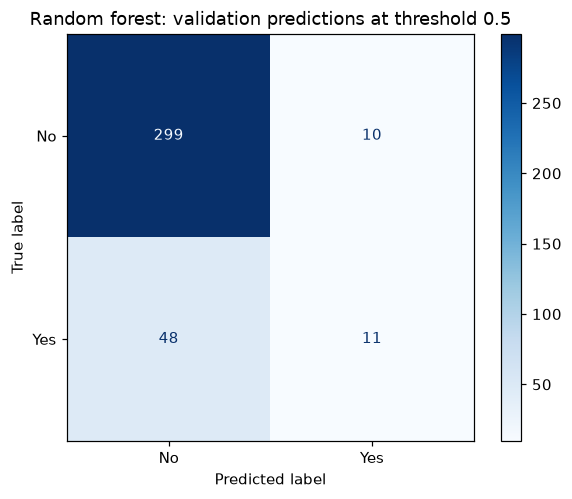

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_valid, probability >= 0.5, display_labels=["No", "Yes"], cmap="Blues"
)
plt.title("Random forest: validation predictions at threshold 0.5")
plt.show()

### Choose the two cases — provided code

Select the validation row with the **highest** model probability and the row with
the **lowest** probability. These are contrasting cases, not a representative
sample of all employees. Their observed labels are shown for comparison, but are
not used to select them. Keep these same cases for LIME and SHAP.

In [13]:
validation_results = pd.DataFrame({"observed": y_valid, "probability": probability})
high_id = validation_results["probability"].idxmax()
low_id = validation_results["probability"].idxmin()
case_ids = [high_id, low_id]
X_cases = X_valid.loc[case_ids]

case_table = X_cases.copy()
case_table.insert(0, "case", ["High probability", "Low probability"])
case_table["observed"] = y_valid.loc[case_ids]
case_table["probability"] = model.predict_proba(X_cases)[:, 1]
display(case_table.round(3))

,case,Age,MonthlyIncome,DistanceFromHome,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,OverTime,observed,probability
EmployeeNumber,,,,,,,,,,,,,
959,High probability,19,2121,21,1,1,0,2,4,4,1,1,0.876
1069,Low probability,46,19627,1,23,2,2,4,4,3,0,0,0.035


### NEW — Task 1: change the classification threshold

**Added 5 October, revision 2.** Keep your earlier results at threshold 0.5.
Write this comparison using the existing forest probabilities for **all
validation rows**. Do not retrain the forest or change `probability`.

1. Loop over thresholds **0.20, 0.35 and 0.50**. At each threshold, predict
   `Yes` when the probability is **greater than or equal to** the threshold.
2. Build and display `threshold_results`, with one row per threshold and columns:
   `threshold`, `accuracy`, `missed attrition`, `false alarms`.
   A missed case is actual Yes / predicted No; a false alarm is actual No /

   predicted Yes. Count rows, not percentages. Use the same row order as `y_valid`.
4. Make **one line plot with markers**, showing both error counts against
   threshold. Label the axes and the two lines.

Use a loop and ordinary comparisons, or a confusion matrix. Your threshold-0.50
row should agree with the original accuracy and confusion matrix. The rest of
the notebook still explains the unchanged **probabilities**, not thresholded labels.

,threshold,accuracy,missed attrition,false alarms
0,0.20,0.774,28,55
1,0.35,0.821,42,24
2,0.50,0.842,48,10


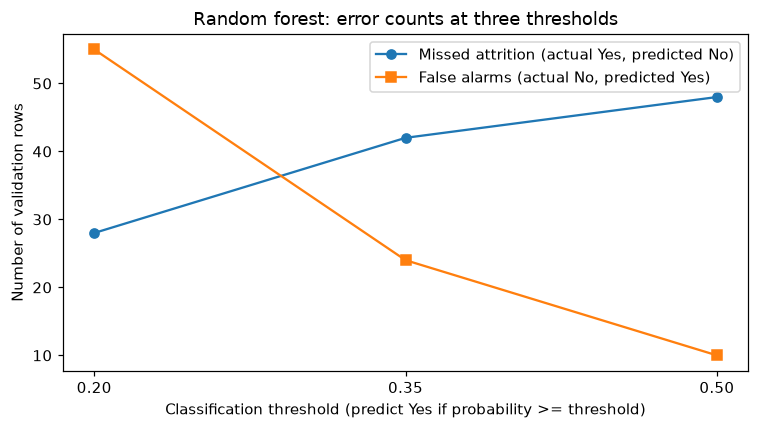

In [14]:
thresholds = [0.20, 0.35, 0.50]

# Write your code: classify, count errors, create threshold_results and plot.


# The forest's probabilities f(x) stay fixed. Only the decision rule changes:
#     predicted Yes  <=>  f(x) >= threshold
# `probability` (numpy array) and `y_valid` are in the same row order, so we compare them position by position.
actual_yes = y_valid.to_numpy() == 1

threshold_rows = []
for threshold in thresholds:
    predicted_yes = probability >= threshold          # True/False for every validation row
    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_valid, predicted_yes),
        # missed attrition = actual Yes AND predicted No  (false negatives)
        "missed attrition": int(np.sum(actual_yes & ~predicted_yes)),
        # false alarm = actual No AND predicted Yes      (false positives)
        "false alarms": int(np.sum(~actual_yes & predicted_yes)),
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

# One line plot with markers showing both error counts against the threshold
plt.figure(figsize=(7, 4))
plt.plot(threshold_results["threshold"], threshold_results["missed attrition"],
         marker="o", label="Missed attrition (actual Yes, predicted No)")
plt.plot(threshold_results["threshold"], threshold_results["false alarms"],
         marker="s", label="False alarms (actual No, predicted Yes)")
plt.xticks(thresholds)
plt.xlabel("Classification threshold (predict Yes if probability >= threshold)")
plt.ylabel("Number of validation rows")
plt.title("Random forest: error counts at three thresholds")
plt.legend()
plt.tight_layout()
plt.show()


### Your answer — Task 1

**Update:** keep answers 1–3. Add answers 4–5 for the new threshold comparison.

1. Compare the two accuracy values and the two AP values. Use the class
   proportions to explain why the baseline can have high accuracy.
   **Answer 1:**

  The baseline (DummyClassifier) ignores feature details and relies entirely on class proportions (predicting the majority class based on the overall percentage of people who stayed vs. quit). Because the dataset is heavily imbalanced, a naive model achieves an 84% accuracy simply by guessing the majority class. 
  The Random Forest yields a nearly identical accuracy because, at a rigid 0.5 classification threshold, it also defaults to predicting "No" for the vast majority of employees, meaning both models correctly predict almost everyone who stays.
 
  Average Precision (AP) measures how well a model sorts people from highest risk to lowest risk, without caring about a fixed 0.5 threshold. 
  The baseline gives every single employee a weak or identical risk score, mixing employees who quit in with those who stay. 
  The Random Forest looks at actual employee data (like workload, tenure, or pay) and assigns much higher risk scores to people who actually quit. 
  As a result, the real quitting cases ranked
  straight to the top of the list, making the model far better at spotting high-risk employees.
   
2. From the confusion matrix, report the number of missed attrition cases
   (actual Yes, predicted No) and false alarms (actual No, predicted Yes).
   Which error is more common at threshold 0.5?

   **Answer 2**

    Missed Attrition Cases (False Negatives | actual Yes, predicted No): 48
    False Alarms (False Positives | actual No, predicted Yes): 10
   
3. Are the two selected cases classified correctly at threshold 0.5? Give their
   IDs and probabilities. Why would a detailed explanation of either case **not**
   prove that its prediction is correct?

  **Answer 3** 
Yes. Employee #959: 87.6%, Employee #1069: 3.5%.
Because the model doesn't give explanation why it chose like that. As it is prediction not ground truth, the model risk is probabilistic. and what if the model made linear assumptions or overfitting. also the results is where the model is most confident but that confidence we don't know if it is near the boundary. 
   
4. **NEW:** Compare thresholds 0.50 and 0.20. How many missed cases are avoided,
   and how many extra false alarms occur? Use the counts to explain the trade-off.
**Answer 4**


0.5: 48 missed cases and 10 false alarms. 0.2: 28 missed cases and 55 false alarms.

   that gives us: 20 missed cases. and 45 additional alarms.

   
   Lowering the threshold makes the decision rule more sensitive. By lowering the required risk cutoff to 0.20, the model catches 20 additional employees who were going to quit. However, the cost of this higher sensitivity is 45 extra false alarms—meaning had no intention of leaving.
   
5. **NEW:** Does changing the threshold change the forest's probabilities or
   retrain the model? Explain why the original average precision stays the same.
   **Answer 5**
   No. Changing the classification threshold does not change the predicted probabilities and does not retrain the model. the model generates fixed probability once. Changing the threshold only modifies the decision rule applied to those static probabilities, whether the risk probability is more than or equal the threshold.
   

## Task 2 — compare the average trend with individual trends

**Update:** keep the original two-feature analysis and answers 1–4. The
overtime-group comparison below and answers 5–6 are **NEW**.

**Question:** Does the PDP describe every row well?

Choose **two different features** from `Age`, `MonthlyIncome`, `DistanceFromHome`
and `YearsAtCompany`. You may keep the two choices below. The provided code uses
the same 50 validation rows for every curve and its average. At each grid value,
it changes only the selected feature; other inputs stay fixed.

Each thin line is an ICE curve. The black line is their point-by-point average:

\[
\operatorname{PDP}_j(t)=\frac{1}{50}\sum_{i=1}^{50}
f(t,x_{i,-j}),
\]

where \(f\) returns the probability of attrition. No model is retrained here.

**Required outputs:** two PDP/ICE plots, the highlighted-row comparison table,
a numerical check of one PDP point, and the **NEW** overtime-group table and plot.

### Starter code 3/5

In `ice`, **rows are employees** and **columns are trial feature values**.
Replace `...` with the axis that averages over employees, giving one mean
probability for each column (`axis=0` or `axis=1`).

In [19]:
plot_features = ["DistanceFromHome", "YearsAtCompany"]  # Choose two from the list above.
plot_rows = X_valid.sample(50, random_state=SEED)
ice_by_feature = {}
pdp_by_feature = {}

for feature in plot_features:
    low, high = X_train[feature].quantile([0.05, 0.95])
    grid = np.unique(np.linspace(low, high, 15).round())
    ice = pd.DataFrame(index=plot_rows.index, columns=grid, dtype=float)
    for value in grid:
        changed = plot_rows.copy()
        changed[feature] = value
        ice[value] = model.predict_proba(changed)[:, 1]
    pdp = ice.mean(axis=0)  # TODO: axis for averaging over employees
    ice_by_feature[feature] = ice
    pdp_by_feature[feature] = pdp

### Plot and compare — provided code

For each feature, highlight the employees with the smallest and largest change
from the first to the last grid value. This helps compare **changes**, not just
different starting probabilities. The rows need not show opposite trends.
These are deliberately selected examples, not typical employees.

Probabilities are shown from 0 to 1. A change from 0.20 to 0.25 is **5 percentage
points (pp)**, not 5% of the starting value.

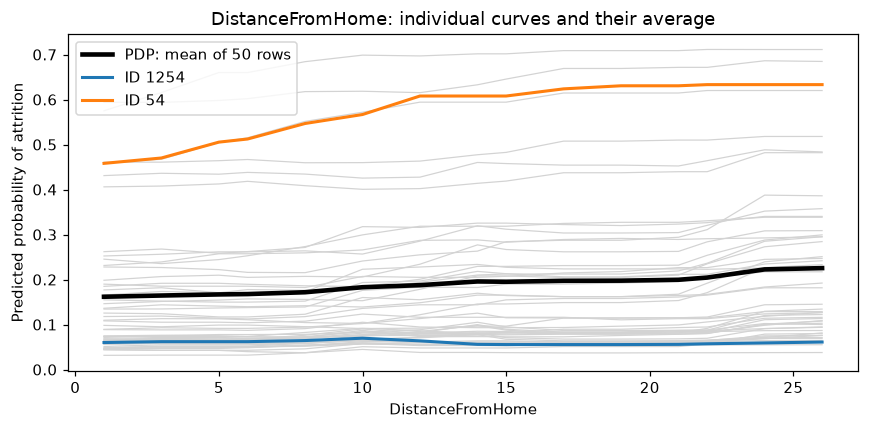

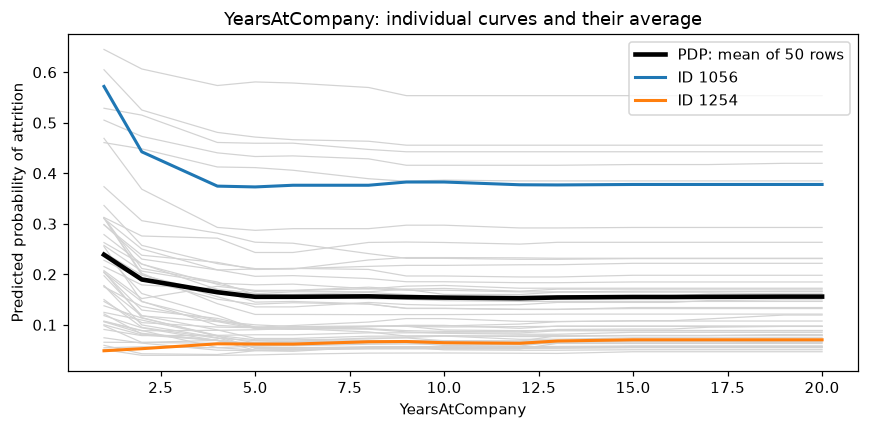

,feature,ID,first value,last value,first probability,last probability,change (pp)
0,DistanceFromHome,1254,1.0,26.0,0.060,0.061,0.104
1,DistanceFromHome,54,1.0,26.0,0.458,0.633,17.496
2,YearsAtCompany,1056,1.0,20.0,0.572,0.378,-19.399
3,YearsAtCompany,1254,1.0,20.0,0.049,0.070,2.174


In [20]:
comparison_rows = []
for feature in plot_features:
    ice = ice_by_feature[feature]
    pdp = pdp_by_feature[feature]
    changes = ice.iloc[:, -1] - ice.iloc[:, 0]
    ordered_ids = changes.sort_values().index
    selected_ids = [ordered_ids[0], ordered_ids[-1]]

    plt.figure(figsize=(8, 4))
    plt.plot(ice.columns, ice.T, color="lightgray", linewidth=0.8)
    plt.plot(pdp.index, pdp, color="black", linewidth=3, label="PDP: mean of 50 rows")
    for employee_id, color in zip(selected_ids, ["tab:blue", "tab:orange"]):
        curve = ice.loc[employee_id]
        plt.plot(ice.columns, curve, color=color, linewidth=2, label=f"ID {employee_id}")
        comparison_rows.append({
            "feature": feature, "ID": employee_id,
            "first value": ice.columns[0], "last value": ice.columns[-1],
            "first probability": curve.iloc[0], "last probability": curve.iloc[-1],
            "change (pp)": 100 * changes.loc[employee_id]
        })
    plt.xlabel(feature)
    plt.ylabel("Predicted probability of attrition")
    plt.title(f"{feature}: individual curves and their average")
    plt.legend()
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(comparison_rows).round(3))

In [21]:
feature = plot_features[0]
pdp = pdp_by_feature[feature]
value = pdp.index[len(pdp) // 2]

changed = plot_rows.copy()
changed[feature] = value
check = model.predict_proba(changed)[:, 1].mean()
print(f"{feature} = {value:g}: direct mean = {check:.6f}; plotted PDP = {pdp.loc[value]:.6f}")

DistanceFromHome = 14: direct mean = 0.195745; plotted PDP = 0.195745


### NEW — Task 2: compare the two overtime groups

**Added 5 October, revision 2.** Keep your earlier PDP/ICE work. Choose **one of
your two plotted features** and reuse its existing ICE matrix and the same 50
`plot_rows`. Do not sample new rows, change the grid or retrain the forest.

Write code to:

1. Split the rows into their original `OverTime` groups: **0 = No**, **1 = Yes**.
   Use employee IDs to select matching rows from `ice_by_feature[group_feature]`.
   Do **not** replace everyone's `OverTime` value.
2. Calculate each group's mean ICE probability **at every grid value**. These
   are two separate group-average curves, not averages over the feature grid.
3. Build and display `overtime_results`, one row per group. Include the group,
   number of rows, first and last grid values, first and last mean probabilities,
   and the change between those probabilities **in percentage points**.
4. Centre each group's curve by subtracting **that same curve's first value**
   from every point. Both centred curves must start at zero.
5. Plot both centred curves in **one figure**, using the common feature grid on
   the horizontal axis. Multiply the centred values by 100 and label the vertical
   axis “Change in predicted probability (percentage points)”. Identify the groups
   in a legend and name the feature in the title.

Use the uncentred probabilities for the table and the centred changes for the
plot. This separates differences in starting level from differences in response.

,rows,first value,last value,first mean probability,last mean probability,change (pp)
group,,,,,,
No overtime,36,1.0,26.0,0.115,0.162,4.762
Overtime,14,1.0,26.0,0.283,0.388,10.471


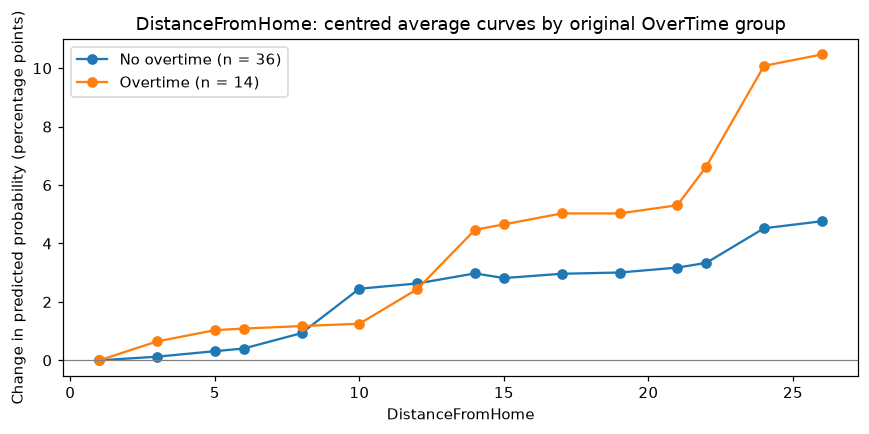

In [22]:
group_feature = plot_features[0]  # You may choose either of your two features.

# Write your code: two group-average curves, overtime_results and a centred plot.

# Reuse the existing ICE matrix: rows = the same 50 employees, columns = the same grid values.
ice = ice_by_feature[group_feature]

group_curves = {}
overtime_rows = []
for code, name in [(0, "No overtime"), (1, "Overtime")]:
    # Select employees by their ORIGINAL OverTime value (nothing is replaced).
    ids = plot_rows.index[plot_rows["OverTime"] == code]
    assert len(ids) > 0, f"No rows in group {name}"
    # Group-average curve: mean over the group's employees at EVERY grid value (axis=0 = over rows)
    curve = ice.loc[ids].mean(axis=0)
    group_curves[name] = (curve, len(ids))
    overtime_rows.append({
        "group": name,
        "rows": len(ids),
        "first value": curve.index[0],
        "last value": curve.index[-1],
        "first mean probability": curve.iloc[0],
        "last mean probability": curve.iloc[-1],
        "change (pp)": 100 * (curve.iloc[-1] - curve.iloc[0]),   # percentage points
    })

overtime_results = pd.DataFrame(overtime_rows).set_index("group")
display(overtime_results.round(3))

# Centred curves: subtract each curve's OWN first value, so both start at 0.
# This removes differences in starting level and leaves only differences in response shape.
plt.figure(figsize=(8, 4))
for name, (curve, n_rows) in group_curves.items():
    centred = curve - curve.iloc[0]
    plt.plot(curve.index, 100 * centred, marker="o", label=f"{name} (n = {n_rows})")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel(group_feature)
plt.ylabel("Change in predicted probability (percentage points)")
plt.title(f"{group_feature}: centred average curves by original OverTime group")
plt.legend()
plt.tight_layout()
plt.show()


### Your answer — Task 2

**Update:** keep answers 1–4. Add answers 5–6 for the new group comparison.

1. For **each feature**, describe the average trend over the plotted range.
   Include the first and last feature values and the corresponding PDP
   probabilities. These are available in `pdp_by_feature[feature]`.
**Answer 1**

a. Distancefromhome feature: 
the starting from 1 to 26 (however the unit is). the probability starts from 16-17% and ended up at around 2%. which implies a steady increase for the trend of the distance.
b. yeasatcompany feature:
the range values from 1 to 20 years. a sharp decline in the first 4-5 years. however, the probability is steady stablized after that till end of the 20.
   
2. For **each feature**, compare the two highlighted employees using their IDs
   and changes in percentage points. Does the average hide differences in
   response? Similar responses are also a valid finding; opposite trends are
   not required. A vertical gap alone does not show a different response shape.
**Answer 2**
a. Distancefromhome (54 vs. 1254)
ID 54 started from 45.8% and ended at 63.3% change around 17.5%
ID 1254 started from 6% to 6.1% change 0.1%
Yes, the average hides strong individual differences. while the huge difference in 54 the 1254 wasn't affected much.

b. YearsAtCompany ( 1056 vs. 1254):
ID 1056: Starts at 0.572 and drops to 0.378 (-19.399 pp).
ID 1254: Starts at 0.049 and ends at 0.070 (+2.174 pp).
Comparison: Yes, the average hides differences. again the employee 1056 ahd huge effect while the other has small difference.
   
3. For the checked PDP point, state what was replaced, what stayed fixed, and
   what was averaged. Give the checked value.
**Answer 3**
DistanceFromHome to 14 for all 50 employees and kept everything else the
   same. The average predicted probability was 0.195745, the same as the PDP value
   at 14.

4. Give one potentially unrealistic input combination that feature replacement
   can create in this dataset. You may use any of the ten model features for
   this example. Explain why the plots alone cannot show that changing a
   feature would cause an employee to stay or leave.
**Answer 4**
When YearsAtCompany is set to 20 for every employee, someone whose TotalWorkingYears is 5 gets 20 years at the company but only 5 years of work in total, which is impossible. The plots only show how the model's prediction changes when we change an input; they do not show that the change would make a real employee stay or leave, because the model learned patterns from the data, not causes.
   
5. **NEW:** Name your feature and report both group sizes and first-to-last
   changes in percentage points. Compare the centred curves' shapes. Similar
   responses are a valid finding; a difference is not required.
**Answer 5**
Using DistanceFromHome (1 to 26). The no-overtime group has 36 employees and its mean probability rises by 4.8 pp (0.115 to 0.162). The overtime group has 14 employees and rises by 10.5 pp (0.283 to 0.388). Both curves rise and are similar at short distances, but the overtime curve rises more at large distances, ending about twice as high.
6. **NEW:** Why subtract each group's own starting value? Does this group
   comparison isolate a causal effect of overtime? Explain using how the groups
   were formed and name one other feature that could differ between them.
**Answer 6**
Each curve starts at a different level (0.115 vs 0.283), so subtracting its own starting value makes both start at 0 and lets us compare only how much they change. This does not show a causal effect of overtime, because the groups were formed by employees' real OverTime values, not assigned at random. The groups can also differ in other features, such as MonthlyIncome, which could explain the difference.

## Task 3 — explain two cases with LIME, then repeat one explanation

**Update:** the original two-case explanations and 3,000-input repeat example
are unchanged. Keep that work. The later 500-versus-5,000 comparison and answer 4
are **NEW** relative to the original notebook, but unchanged from revision 1.

**Question:** How well does a local explanation describe this fixed model?

LIME creates modified inputs, obtains the forest's probabilities, and fits a
weighted local linear model. Here it turns numerical features into interval
indicators. A condition's weight belongs to **being in the displayed interval
or category**, not to a one-unit change in the original feature.

We tell LIME that the three 1–4 scores and `OverTime` are categories, so it does
not generate fractional score values. All ten features enter the local fit.

Check two different things:

- **Target gap:** absolute difference between the forest probability and the
  local model's prediction for this employee.
- **Weighted R²:** how well the local model fits the forest's probabilities on
  LIME's generated inputs, using LIME's weights. It is measured on those fitting
  inputs, not on validation outcomes. Higher is better; a small target gap does
  not guarantee a high weighted R².

**Required outputs:** two LIME plots with their three strongest weights, a
two-case fidelity table, and two small tables comparing three new seeds on the
high-probability case. Also complete the **NEW** six-run sample-count comparison,
its summary table and dot plot below. Do not retrain the forest.

### LIME setup — provided code

The first function converts LIME's arrays back into a table with our column
names. It returns probabilities for **both classes**, as LIME requires.
The second function creates an explainer using a specified random seed.

In [23]:
def predict_probability(rows):
    rows = pd.DataFrame(rows, columns=FEATURES)
    return model.predict_proba(rows)


category_columns = ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "OverTime"]
category_positions = [FEATURES.index(name) for name in category_columns]


def make_lime(seed):
    return LimeTabularExplainer(
        X_train.to_numpy(), feature_names=FEATURES,
        class_names=["No attrition", "Attrition"], mode="classification",
        categorical_features=category_positions,
        categorical_names={FEATURES.index("OverTime"): ["No", "Yes"]},
        discretize_continuous=True, feature_selection="none", random_state=seed
    )

### Starter code 4/5

Replace `...` with the **function name** that lets LIME obtain the model's
probabilities for its generated inputs. Use the function defined above; do not
call it yourself here. `labels=(1,)` asks LIME to explain attrition only.

In [25]:
lime_explanations = {}
fidelity_rows = []
for employee_id in case_ids:
    explanation = make_lime(SEED).explain_instance(
        X_valid.loc[employee_id].to_numpy(), predict_probability,  # TODO: probability function
        labels=(1,), num_features=len(FEATURES), num_samples=3000
    )
    lime_explanations[employee_id] = explanation
    model_p = validation_results.loc[employee_id, "probability"]
    local_p = float(explanation.local_pred[0])
    fidelity_rows.append({
        "ID": employee_id, "model probability": model_p,
        "local prediction": local_p, "absolute gap": abs(model_p - local_p),
        "weighted R2": explanation.score
    })
display(pd.DataFrame(fidelity_rows).round(4))

,ID,model probability,local prediction,absolute gap,weighted R2
0,959,0.8760,0.4308,0.4453,0.5957
1,1069,0.0351,0.0395,0.0045,0.4610


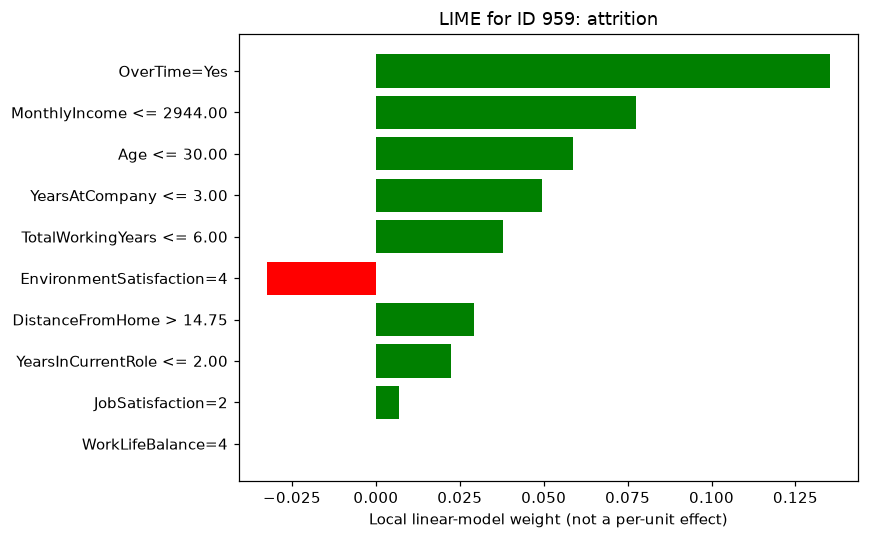

,condition,weight
0,OverTime=Yes,0.1352
1,MonthlyIncome <= 2944.00,0.0775
2,Age <= 30.00,0.0587


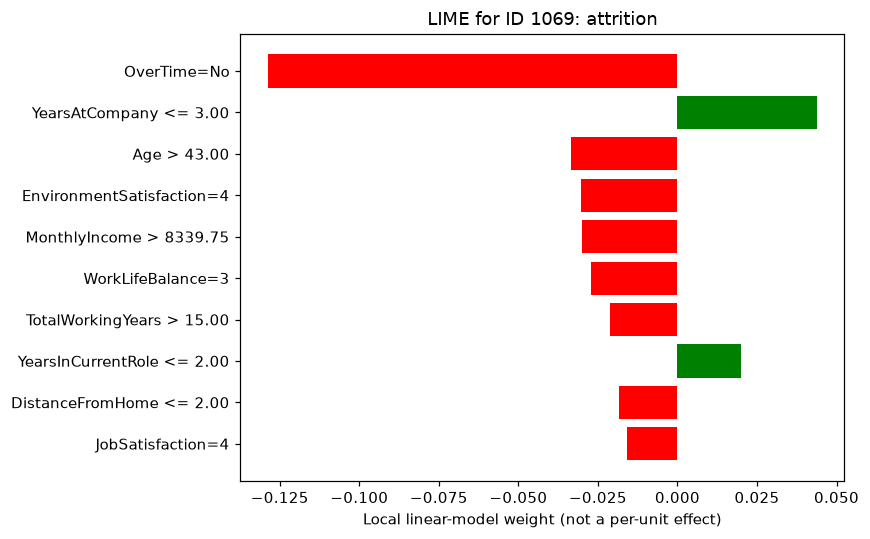

,condition,weight
0,OverTime=No,-0.1288
1,YearsAtCompany <= 3.00,0.0438
2,Age > 43.00,-0.0335


In [26]:
for employee_id in case_ids:
    explanation = lime_explanations[employee_id]
    fig = explanation.as_pyplot_figure(label=1)
    fig.set_size_inches(8, 5)
    plt.title(f"LIME for ID {employee_id}: attrition")
    plt.xlabel("Local linear-model weight (not a per-unit effect)")
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame(explanation.as_list(label=1)[:3],
                         columns=["condition", "weight"]).round(4))

### Repeat LIME with different seeds — provided code

The next cell changes only LIME's random seed, keeping the forest, employee and
number of generated inputs fixed.

In [27]:
lime_seed_rows = []
lime_condition_rows = []
for seed in [11, 22, 33]:
    explanation = make_lime(seed).explain_instance(
        X_valid.loc[high_id].to_numpy(), predict_probability,
        labels=(1,), num_features=len(FEATURES), num_samples=3000
    )
    model_p = validation_results.loc[high_id, "probability"]
    lime_seed_rows.append({
        "seed": seed, "model probability": model_p,
        "local prediction": float(explanation.local_pred[0]),
        "absolute gap": abs(model_p - float(explanation.local_pred[0])),
        "weighted R2": explanation.score
    })
    for condition, weight in explanation.as_list(label=1)[:3]:
        lime_condition_rows.append({"seed": seed, "condition": condition, "weight": weight})

display(pd.DataFrame(lime_seed_rows).round(4))
display(pd.DataFrame(lime_condition_rows).round(4))

,seed,model probability,local prediction,absolute gap,weighted R2
0,11,0.876,0.4314,0.4447,0.5963
1,22,0.876,0.4388,0.4373,0.6145
2,33,0.876,0.4411,0.4349,0.6063


,seed,condition,weight
0,11,OverTime=Yes,0.1444
1,11,MonthlyIncome <= 2944.00,0.0770
2,11,Age <= 30.00,0.0540
3,22,OverTime=Yes,0.1476
4,22,MonthlyIncome <= 2944.00,0.0702
5,22,Age <= 30.00,0.0595
6,33,OverTime=Yes,0.1410
7,33,MonthlyIncome <= 2944.00,0.0759
8,33,Age <= 30.00,0.0607


### NEW — Task 3 continued: does using more generated inputs help?

**Added 5 October, revision 1; unchanged in revision 2.** If you completed this
six-run comparison already, keep it. This is additional work, not a replacement
for the original 3,000-input repeat example.

The previous cell is a worked example. Now **write your own comparison** for
the same `high_id` employee and the same forest:

1. Use **500 and 5,000 generated inputs**, each with seeds **11, 22 and 33**:
   six LIME fits in total. Make a new explainer for each fit. Change
   `num_samples`; keep `labels=(1,)`, all ten features and other settings fixed.
2. Track **one fixed condition**: the condition with the largest absolute weight
   in the original seed-42 explanation. Do not choose a new condition in each run.
3. Build and display `lime_sample_results`, with one row per fit and columns:
   `samples`, `seed`, `absolute gap`, `weighted R2`, `tracked weight`.

Use `make_lime(seed)` and `explain_instance` as in the worked example. To get
the weight of a named condition, `dict(explanation.as_list(label=1))[tracked_condition]`
converts the condition–weight pairs into a lookup. All conditions are included
because the supplied explainer uses all ten features.

**Your code:** write the loops, collect the results and create the table below.

In [29]:
sample_counts = [500, 5000]
experiment_seeds = [11, 22, 33]
tracked_condition = lime_explanations[high_id].as_list(label=1)[0][0]
print("Tracked condition:", tracked_condition)

# Write your code: six LIME fits, then create and display lime_sample_results.
model_p = validation_results.loc[high_id, "probability"]

lime_sample_rows = []
for samples in sample_counts:
    for seed in experiment_seeds:
        explanation = make_lime(seed).explain_instance(        # new explainer for every fit
            X_valid.loc[high_id].to_numpy(), predict_probability,
            labels=(1,), num_features=len(FEATURES), num_samples=samples
        )
        local_p = float(explanation.local_pred[0])          # g(x') for the target employee
        weights = dict(explanation.as_list(label=1))        # condition -> weight lookup
        lime_sample_rows.append({
            "samples": samples,
            "seed": seed,
            "absolute gap": abs(model_p - local_p),
            "weighted R2": explanation.score,                # fit on THIS run's generated inputs
            "tracked weight": weights[tracked_condition],    # same condition in every run
        })

lime_sample_results = pd.DataFrame(lime_sample_rows)
display(lime_sample_results.round(4))


Tracked condition: OverTime=Yes


,samples,seed,absolute gap,weighted R2,tracked weight
0,500,11,0.3983,0.6518,0.1498
1,500,22,0.4086,0.6428,0.1464
2,500,33,0.4179,0.6338,0.1486
3,5000,11,0.4292,0.6034,0.1403
4,5000,22,0.4568,0.5971,0.1411
5,5000,33,0.4340,0.5990,0.1399


### NEW — summarise your LIME comparison: your code

**Part of the new Task 3 sample-count comparison.** Keep this work if completed
in revision 1.

Using `lime_sample_results`:

- Build and display `lime_sample_summary`, with one row per sample count.
  Include the **mean absolute gap**, **mean weighted R²**, and the tracked
  weight's **minimum**, **maximum** and **range** across the three seeds.
  Here, range means maximum minus minimum; use signed weights, not their
  absolute values.
- Make **one dot plot**: sample count on the horizontal axis and tracked weight
  on the vertical axis. Plot all six runs, not just the two means. Label the
  axes and name the tracked condition in the title.

A loop over the two sample counts and ordinary column operations are enough.
Do not build a general experiment framework.
Each R² comes from that run's generated fitting inputs, not a shared held-out
sample. Do not present this as a test of prediction accuracy.

,mean absolute gap,mean weighted R2,tracked weight min,tracked weight max,tracked weight range
samples,,,,,
500,0.4082,0.6428,0.1464,0.1498,0.0034
5000,0.4400,0.5998,0.1399,0.1411,0.0012


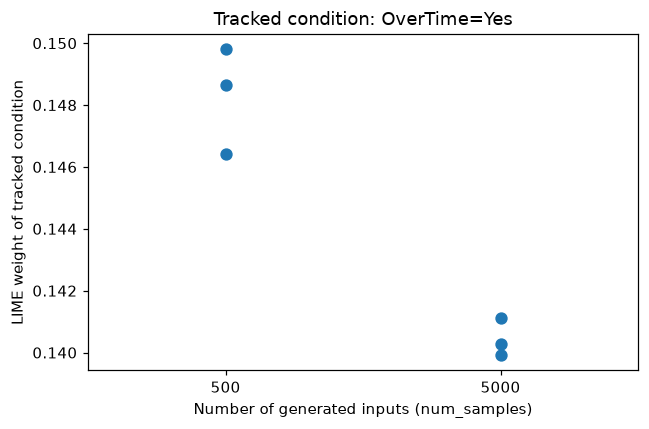

In [30]:
# Write your code: a two-row summary table and one dot plot.
# One summary row per sample count (3 seeds each)
summary_rows = []
for samples in sample_counts:
    runs = lime_sample_results[lime_sample_results["samples"] == samples]
    w = runs["tracked weight"]                      # signed weights, not absolute values
    summary_rows.append({
        "samples": samples,
        "mean absolute gap": runs["absolute gap"].mean(),
        "mean weighted R2": runs["weighted R2"].mean(),
        "tracked weight min": w.min(),
        "tracked weight max": w.max(),
        "tracked weight range": w.max() - w.min(),   # max - min across the three seeds
    })
lime_sample_summary = pd.DataFrame(summary_rows).set_index("samples")
display(lime_sample_summary.round(4))

# Dot plot: all six runs (not only the means)
positions = {count: k for k, count in enumerate(sample_counts)}
plt.figure(figsize=(6, 4))
plt.scatter(lime_sample_results["samples"].map(positions),
            lime_sample_results["tracked weight"], s=50)
plt.xticks(list(positions.values()), [str(c) for c in sample_counts])
plt.xlim(-0.5, len(sample_counts) - 0.5)
plt.xlabel("Number of generated inputs (num_samples)")
plt.ylabel("LIME weight of tracked condition")
plt.title(f"Tracked condition: {tracked_condition}")
plt.tight_layout()
plt.show()


### Your answer — Task 3

**Update:** answers 1–3 address the same original results; their wording now
specifies which runs to use. Answer 4 is **NEW** from revision 1.

1. For **each employee's original seed-42 explanation**, quote the condition with the largest absolute LIME
   weight, its weight and its sign. Explain what the sign means in this local
   model. If it is an interval condition, explain why the weight is not the
   change in probability for one extra year or income unit.
**Answer 1**
ID 959: the largest weight is OverTime=Yes, +0.1352. ID 1069: the largest weight is OverTime=No, -0.1288. A positive sign means this condition pushes the local model's predicted probability up (about +13.5 pp for 959); a negative sign pushes it down (about -12.9 pp for 1069). Both are categories, not intervals. For an interval condition such as MonthlyIncome <= 2944, the weight compares being inside the interval with being outside it, so it is not the change for one extra unit of income.

2. Compare the two original 3,000-input explanations' target gaps and weighted R² values. How well does
   each local model reproduce the forest at the target and around it? Refer
   to the numbers; do not use a made-up pass/fail threshold for R².
**Answer 2**
ID 959: the forest gives 0.876 but the local model gives 0.431, a gap of 0.445, with weighted R2 = 0.596. ID 1069: the forest gives 0.035 and the local model 0.040, a gap of only 0.005, with weighted R2 = 0.461. So for 959 the local model misses the forest badly at the employee itself, while for 1069 it is very close at the employee but explains less of the forest's behaviour around it.

3. In the provided 3,000-input repeat example, which leading conditions and
   signs persist across the three seeds, and what changes? Use its tables. Is this evidence
   about explanation stability, prediction accuracy, or both? Explain briefly.
**Answer 3**
In all three seeds (11, 22, 33) the same three conditions appear in the same order with the same positive signs: OverTime=Yes, MonthlyIncome <= 2944 and Age <= 30. Only the sizes change a little (OverTime 0.141 to 0.148). This is evidence about explanation stability only, not prediction accuracy, because the forest and its prediction (0.876) never change and the real outcome is not used.

4. **NEW:** In your 500-versus-5,000 comparison, did more generated inputs reduce the
   tracked weight's range? Did the mean gap and mean weighted R² improve?
   Quote the summary values. Explain why a stable weight alone does not show
   that the local model fits well. Report the observed result even if more
   inputs did not improve every measure.
**Answer 4**
Yes, the tracked weight (OverTime=Yes) became more stable: its range fell from 0.0034 with 500 inputs to 0.0012 with 5,000. But the fit did not improve: the mean gap went from 0.4082 to 0.4400 and the mean weighted R2 from 0.6428 to 0.5998. A stable weight only means LIME gives a similar answer each time; the local model can still be a poor copy of the forest, as the 0.44 gap shows

## Task 4 — explain the probability with SHAP and change the background

**REVISED — 5 October, revision 1; unchanged in revision 2.** Keep existing
SHAP results and adapt your code where needed. The plots and contribution table
are the same outputs as before, but now have implementation blocks. The
background-mean check, 20-row backgrounds, range summary and dot plot are added.

**Question:** What is the prediction compared with, and does that choice matter?

Use TreeSHAP for the same forest and the same two validation employees. For these
first explanations, the background is **100 randomly sampled training rows**, not the employees being
explained. It supplies the comparison inputs when a coalition lacks features.
The base value is the forest's average attrition probability on this background.

We explicitly request probability output. The explanation must satisfy

\[
f(x)=\phi_0+\sum_j\phi_j.
\]

A SHAP value of `+0.03` adds **3 percentage points** relative to the base value;
it is not a 3% relative increase and not a causal effect.

**Required outputs:** two waterfall plots, a contribution table, a numerical
reconstruction table, a check of the base value, and a background-size comparison
with a six-row results table, a two-row range table and one dot plot.

### 4A. Calculate SHAP values — provided API example

`[:, :, 1]` selects class 1 (attrition) from the output: employees × features × classes.
The `interventional` setting specifies the background-replacement approach used
in the lectures. Replacements can still create unrealistic feature combinations.

In [31]:
background = X_train.sample(100, random_state=SEED)
explainer = shap.TreeExplainer(
    model, data=background, feature_perturbation="interventional",
    model_output="probability"
)
shap_values = explainer(X_cases)[:, :, 1]

### REVISED — present the two explanations: your code

**Same outputs; code is now for you to write.** If your previous plots and
table already meet the requirements below, keep them and adapt existing code.

Write code to:

1. Produce **one waterfall plot for each employee** in `case_ids`, with the
   employee ID in the title and all ten features shown. For one explanation,
   the plotting call is `shap.plots.waterfall(shap_values[position], max_display=10, show=False)`.
   Add a title and show the figure, as in the earlier plotting cells.
2. Create and display `shap_contributions`: a table with **ten feature rows and
   two employee-ID columns**. `shap_values.values` contains the contributions
   with employees as rows and features as columns; transpose it for this table.
   Keep signed values. Display four decimal places.

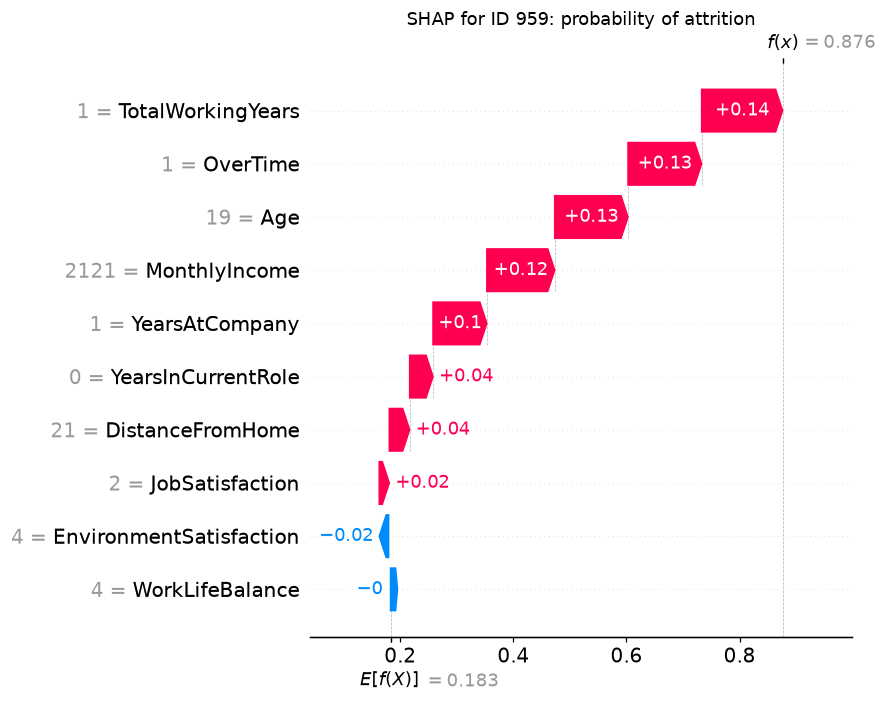

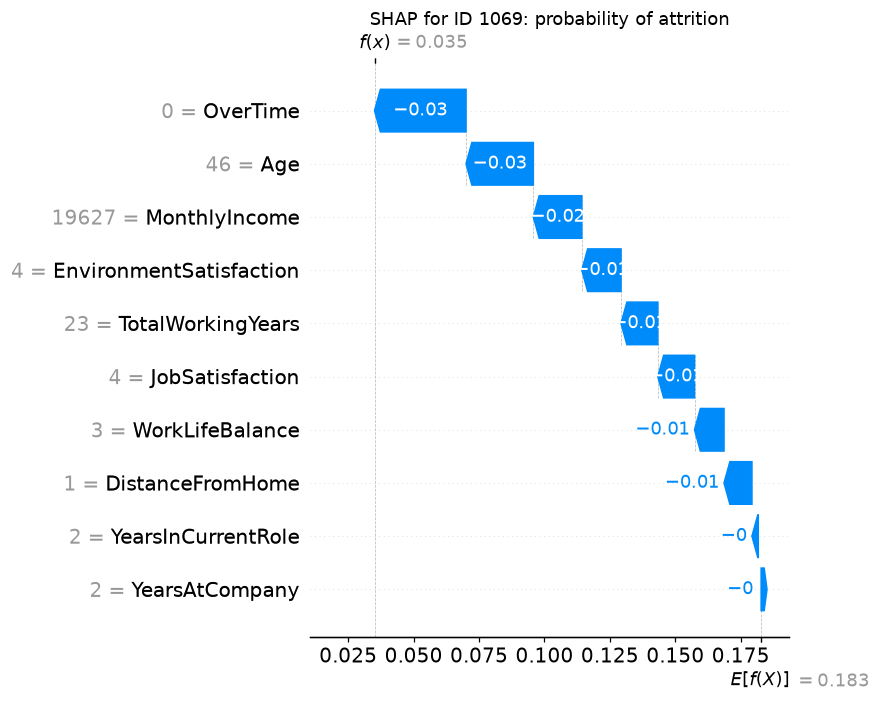

ID,959,1069
Age,0.1296,-0.0257
MonthlyIncome,0.1200,-0.0185
DistanceFromHome,0.0360,-0.0107
TotalWorkingYears,0.1432,-0.0141
YearsAtCompany,0.0952,-0.0011
YearsInCurrentRole,0.0413,-0.0024
JobSatisfaction,0.0178,-0.0140
EnvironmentSatisfaction,-0.0166,-0.0150
WorkLifeBalance,-0.0034,-0.0113
OverTime,0.1302,-0.0350


In [32]:
# Write your code: two waterfall plots and the shap_contributions table.
# 1. One waterfall plot per employee, all ten features shown
for position, employee_id in enumerate(case_ids):
    shap.plots.waterfall(shap_values[position], max_display=10, show=False)
    plt.title(f"SHAP for ID {employee_id}: probability of attrition")
    plt.tight_layout()
    plt.show()

# 2. shap_values.values has shape (employees, features) = (2, 10).
#    Transpose -> (10, 2): ten feature rows, one column per employee ID. Signed values kept.
shap_contributions = pd.DataFrame(shap_values.values.T, index=FEATURES, columns=case_ids)
shap_contributions.columns.name = "ID"
display(shap_contributions.round(4))


### REVISED — 4B. Check the numbers: starter code 5/5 and your implementation

Keep an existing reconstruction table and check if they meet points 1–4 below.
Point 5, the **background-mean check, is NEW**. The full check is now an
implementation block rather than supplied code.

`shap_values.values` has one row per employee and one column per feature.
Replace `...` with the axis that adds the feature contributions for each
employee (`axis=0` or `axis=1`). **Then write the rest of the check yourself:**

1. Calculate `reconstructed`: base value plus the sum of **all ten** contributions
   for each employee. The base values are in `shap_values.base_values`.
2. Calculate `case_probability` directly from the forest for `X_cases`, class 1.
3. Display a two-row table named `shap_check`, indexed by `case_ids`, with the
   base, sum of contributions, reconstructed probability, model probability and
   absolute difference between the last two. Display six decimal places.
4. Check that both absolute differences are below **0.000001**. Print the
   largest difference and whether this check passes.
5. **NEW:** Calculate the forest's **mean class-1 probability on `background`**. Print it
   beside the SHAP base and check agreement to the same tolerance. Average
   model probabilities, not the observed attrition labels.

Keep the same employee order in every calculation. These checks test that you
have read the explanation correctly; they do not test predictive accuracy.

In [35]:
contribution_sum = shap_values.values.sum(axis=1)  # TODO: axis for adding features

# Write your code: reconstruction table, numerical check and background-mean check.
# 1. Efficiency property: f(x) = base + sum of all ten contributions
base = shap_values.base_values
reconstructed = base + contribution_sum

# 2. Probability directly from the forest, class 1, same employee order
case_probability = model.predict_proba(X_cases)[:, 1]

# 3. Two-row check table
shap_check = pd.DataFrame({
    "base": base,
    "sum of contributions": contribution_sum,
    "reconstructed probability": reconstructed,
    "model probability": case_probability,
    "absolute difference": np.abs(reconstructed - case_probability),
}, index=case_ids)
shap_check.index.name = "ID"
display(shap_check.round(6))

# 4. Tolerance check
largest_difference = shap_check["absolute difference"].max()
print(f"Largest reconstruction difference: {largest_difference:.2e}; "
      f"check passes (< 1e-6): {largest_difference < 1e-6}")

# 5. NEW: the base should be the forest's MEAN PROBABILITY on the background rows (not the labels)
background_mean = model.predict_proba(background)[:, 1].mean()
shap_base = float(base[0])
print(f"Mean forest probability on background: {background_mean:.6f}; SHAP base: {shap_base:.6f}")
print(f"Background-mean check passes (< 1e-6): {abs(background_mean - shap_base) < 1e-6}")

,base,sum of contributions,reconstructed probability,model probability,absolute difference
ID,,,,,
959,0.182784,0.693261,0.876045,0.876045,0.0
1069,0.182784,-0.147724,0.035059,0.035059,0.0


Largest reconstruction difference: 2.53e-09; check passes (< 1e-6): True
Mean forest probability on background: 0.182784; SHAP base: 0.182784
Background-mean check passes (< 1e-6): True


### REVISED — 4C. Compare background sizes: your code

The original comparison used three 100-row backgrounds. **Keep those runs** if
you have them; extend your code with three **NEW 20-row runs** and combine the
six results in one table. Do not redo correct 100-row calculations unnecessarily.

Explain the **same high-probability employee** using training-background samples
of **20 and 100 rows**, each with seeds **11, 22 and 33**. This gives six
explanations. Keep the forest fixed; do not retrain it.

The code below selects the three largest absolute contributions from the
original seed-42 explanation. Track these **same three features** in every run.

Write the loops to:

1. Sample the stated number of rows from `X_train` using the stated seed.
2. Create a new `TreeExplainer` for that background, with the same probability
   output and replacement settings as in 4A.
3. Explain `X_valid.loc[[high_id]]` and select class 1. Double brackets keep this
   as a one-row table. After class selection, `result.values[0]` contains ten
   contributions and `result.base_values[0]` is the base.
4. Build and display `background_results`, one row per explanation, containing:
   background size, seed, base, reconstructed probability, model probability
   and a signed SHAP column for each of the three tracked features.
5. Check that all six reconstructed probabilities match the model probability
   within **0.000001**. Use **all ten contributions** in the reconstruction,
   not only the three displayed features.

Keep the original `shap_values` unchanged for the final LIME–SHAP comparison.

In [36]:
first_values = pd.Series(shap_values[0].values, index=FEATURES)
tracked_features = first_values.abs().nlargest(3).index.tolist()
background_sizes = [20, 100]
experiment_seeds = [11, 22, 33]

# Write your code: six explanations, the background_results table and the check.
model_p = validation_results.loc[high_id, "probability"]

background_rows = []
for size in background_sizes:
    for seed in experiment_seeds:
        bg = X_train.sample(size, random_state=seed)                  # 1. new background sample
        bg_explainer = shap.TreeExplainer(                            # 2. same settings as 4A
            model, data=bg, feature_perturbation="interventional",
            model_output="probability"
        )
        result = bg_explainer(X_valid.loc[[high_id]])[:, :, 1]        # 3. one-row table, class 1
        contributions = pd.Series(result.values[0], index=FEATURES)
        base_value = float(result.base_values[0])
        row = {
            "background size": size,
            "seed": seed,
            "base": base_value,
            "reconstructed probability": base_value + contributions.sum(),  # ALL ten features
            "model probability": model_p,
        }
        for feature in tracked_features:                               # 4. signed tracked values
            row[f"SHAP {feature}"] = contributions[feature]
        background_rows.append(row)

background_results = pd.DataFrame(background_rows)
display(background_results.round(4))

# 5. Reconstruction check for all six runs
max_difference = (background_results["reconstructed probability"]
                  - background_results["model probability"]).abs().max()
print(f"Largest reconstruction difference over six runs: {max_difference:.2e}; "
      f"check passes (< 1e-6): {max_difference < 1e-6}")


,background size,seed,base,reconstructed probability,model probability,SHAP TotalWorkingYears,SHAP OverTime,SHAP Age
0,20,11,0.1196,0.876,0.876,0.1600,0.1392,0.1380
1,20,22,0.1285,0.876,0.876,0.1442,0.1641,0.1314
2,20,33,0.2221,0.876,0.876,0.1348,0.1415,0.1001
3,100,11,0.1644,0.876,0.876,0.1418,0.1390,0.1234
4,100,22,0.1687,0.876,0.876,0.1428,0.1350,0.1216
5,100,33,0.1727,0.876,0.876,0.1362,0.1376,0.1253


Largest reconstruction difference over six runs: 7.75e-09; check passes (< 1e-6): True


### NEW — summarise background sensitivity: your code

**Added 5 October, revision 1; unchanged in revision 2.** The range table and
dot plot supplement the background-results table; they do not replace it.

Using `background_results`:

- Display `background_summary` with **one row per background size**. For the
  base and each of the three tracked features, calculate the range across
  seeds: **100 × (maximum − minimum)**. These four ranges are in percentage
  points; label them accordingly.
- Make **one dot plot** for `tracked_features[0]`: background size on the
  horizontal axis and its SHAP value **in percentage points** on the vertical
  axis. Show all six runs and name the feature in the title.

Compare the ranges within each background size, not across all six runs at once.
With only three seeds per size, this is a small sensitivity check, not a
confidence interval or a guarantee that a larger background is always better.

,base range (pp),SHAP TotalWorkingYears range (pp),SHAP OverTime range (pp),SHAP Age range (pp)
background size,,,,
20,10.246,2.521,2.489,3.788
100,0.833,0.661,0.398,0.367


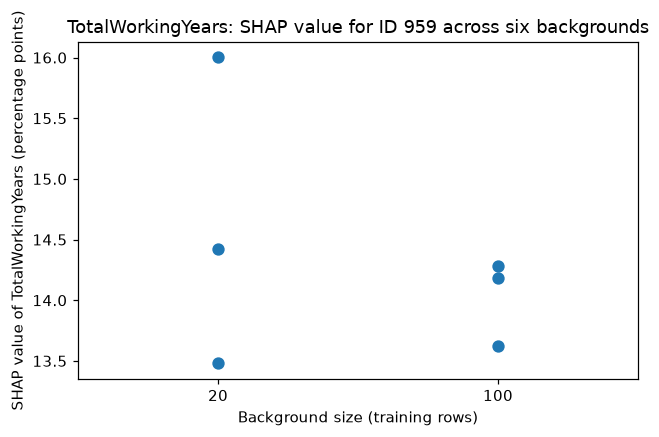

In [37]:
# Write your code: a two-row range table and one dot plot.
# Range across the three seeds, separately for each background size, in percentage points
range_columns = ["base"] + [f"SHAP {feature}" for feature in tracked_features]

summary_rows = []
for size in background_sizes:
    runs = background_results[background_results["background size"] == size]
    row = {"background size": size}
    for column in range_columns:
        row[f"{column} range (pp)"] = 100 * (runs[column].max() - runs[column].min())
    summary_rows.append(row)

background_summary = pd.DataFrame(summary_rows).set_index("background size")
display(background_summary.round(3))

# Dot plot for the first tracked feature: all six runs, in percentage points
feature0 = tracked_features[0]
positions = {size: k for k, size in enumerate(background_sizes)}
plt.figure(figsize=(6, 4))
plt.scatter(background_results["background size"].map(positions),
            100 * background_results[f"SHAP {feature0}"], s=50)
plt.xticks(list(positions.values()), [str(s) for s in background_sizes])
plt.xlim(-0.5, len(background_sizes) - 0.5)
plt.xlabel("Background size (training rows)")
plt.ylabel(f"SHAP value of {feature0} (percentage points)")
plt.title(f"{feature0}: SHAP value for ID {high_id} across six backgrounds")
plt.tight_layout()
plt.show()


### Your answer — Task 4

**Update:** keep the original interpretation in answer 1. Answer 2 is **REVISED**
to compare both background sizes. Answer 3 expands the previous explanation of
what changes, adding the **NEW** background-mean check. Answer 4 is the original
LIME–SHAP comparison (previously answer 3); keep it if it still fits your results.

1. For the **high-probability employee's original seed-42 SHAP explanation**, report the base and model probability.
   Identify the strongest positive and strongest negative SHAP contributions
   and interpret each in percentage points. If one sign is absent, state that.
   What does the reconstruction check establish, and what does it **not**
   establish about the prediction?
**Answer 1**
For ID 959 the base is 0.183 and the model probability is 0.876. The strongest positive contribution is TotalWorkingYears, +14.3 pp, and the strongest negative is EnvironmentSatisfaction, -1.7 pp. The reconstruction check shows that base + all contributions equals the model probability (difference 2.5e-9), so we read the explanation correctly. It does not show that the prediction is correct or that these features cause the employee to leave.

2. **REVISED:** Compare the base-value ranges for 20 and 100 background rows. Which tracked
   feature has the largest SHAP range at each size? Quote the ranges in
   percentage points. Does the larger background reduce variation for every
   tracked feature in your experiment? A finding of no improvement is valid.
**Answer 2**

The base range was 10.25 pp with 20 background rows and 0.83 pp with 100 rows. With 20 rows, Age has the largest range (3.79 pp); with 100 rows, TotalWorkingYears has the largest (0.66 pp). The larger background reduced the variation for every tracked feature: TotalWorkingYears 2.52 to 0.66, OverTime 2.49 to 0.40 and Age 3.79 to 0.37 pp.

   
3. **REVISED:** Did the model probability change across the six backgrounds? Explain why a
   contribution can change while the model and employee stay fixed. How does
   your background-mean check help explain what the base represents?
**Answer 3**
No, the model probability stayed 0.876 in all six runs. The contributions change because SHAP compares the employee with the background rows: a different background gives a different base, and since the contributions must add up to 0.876 minus the base, they change too. The background-mean check shows that the base (0.182784) is exactly the forest's average predicted probability on the background rows, so the base is the "average employee" the prediction is compared with.

4. For the **high-probability employee**, compare the original LIME and SHAP
   explanations (seed 42). Identify one agreement or difference involving a
   named feature. Why need they not have identical weights or rankings?
   Use what each method explains, not just “they are different methods”.
**Answer 4**

Both methods agree that OverTime raises ID 959's probability (LIME +0.135, SHAP +0.130). But TotalWorkingYears is the top SHAP feature (+0.143) and is not in LIME's top three. They differ because SHAP splits the exact difference between this employee's probability and the background average across the features' real values, while LIME fits an approximate simple model on "inside / outside the interval" conditions, which here fits only partly (R2 0.60, gap 0.45).

## Before submission

- Complete the five starter-code gaps, all **Your code** implementation blocks
  and all **Your answer** sections. The original gap count does not include
  the implementation blocks in Tasks 1–4.
- If you started an older version, use the update guide and **NEW / REVISED**
  labels to check your additions. Keep unchanged completed work.
- Include the calculations that produce the required tables and plots for all
  four tasks. Check that your written values match your chosen features and cases.
- Restart the kernel and run the completed notebook from top to bottom to check
  that it works. Saving outputs is useful for reading, but a missing cached
  output is not itself an error in your method.
- Submit the **notebook only**, using the Moodle activity and deadline provided
  by the lecturer. No separate report or results spreadsheet is required.

## Sources

- [IBM fictional employee attrition dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)
- [scikit-learn: PDP and ICE](https://scikit-learn.org/stable/modules/partial_dependence.html)
- [LIME documentation](https://lime-ml.readthedocs.io/en/latest/lime.html)
- [SHAP TreeExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html)